# Summarize hyperparameter optimization results

In [1]:
import matplotlib.pyplot as plt
import scanpy as sc
import anndata as ad
import numpy as np
import scipy
import seaborn as sns
import pandas as pd
import json
import glob

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arialbd.ttf')
bold_prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arialbd.ttf')

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


Load metric values under default hyperparameters

In [2]:
rows = []
for ff in glob.glob('../results/optuna_jsons/default_metrics/*.json'):
    with open(ff, 'r') as f:
        data = json.load(f)
        
    vals = data['default_metrics']
    rows.append([
        data["study_name"].split('_')[0],
        data["dataset_name"],
        vals.get("bio_score"),
        vals.get("batch_score"),
        vals.get("joint_score")
    ])

In [3]:
default = pd.DataFrame(rows, columns=['Integration', 'Dataset', 'BIO', 'BATCH', "OVERALL"])

Load metric values under optimized hyperparameters

In [4]:
rows = []
for ff in glob.glob('../results/optuna_jsons/optimal_metrics/*.json'):
    with open(ff, 'r') as f:
        data = json.load(f)
        
    vals = data['best_metrics']
    rows.append([
        data["study_name"].split('_')[0],
        data["dataset_name"],
        vals.get("bio_score"),
        vals.get("batch_score"),
        vals.get("joint_score")
    ])

In [5]:
optim = pd.DataFrame(rows, columns=['Integration', 'Dataset', 'BIO', 'BATCH', "OVERALL"])

In [6]:
default['Scenario'] = 'Default'
optim['Scenario'] = 'Best'

In [7]:
df = pd.concat([default, optim])

In [8]:
df['Integration'] = df['Integration'].replace({
    'cca': "CCA", 'harmony': "Harmony", 'scvi': 'scVI',
    'liger': "LIGER", 'scanorama': "Scanorama"
})
df['Dataset'] = df['Dataset'].replace({'nph_cerebellum': 'nhp_cerebellum',
                                       'human_pbmc_sequencing_techs': 'human_pbmc_seq_techs'})

In [9]:
per_method = df.groupby(['Integration', 'Scenario'])[['BIO', 'BATCH', 'OVERALL']].mean().reset_index()

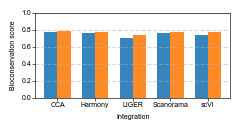

In [84]:
integrations = per_method['Integration'].unique()
x = np.arange(len(integrations))
width = 0.35

best_vals = per_method[per_method['Scenario'] == 'Best'].set_index('Integration').loc[integrations, 'BIO']
default_vals = per_method[per_method['Scenario'] == 'Default'].set_index('Integration').loc[integrations, 'BIO']

fig, ax = plt.subplots(figsize=(2.5, 1.4))
ax.bar(x - width/2, default_vals, width, label='Default', color='#1F77B4', alpha=.9)
ax.bar(x + width/2, best_vals, width, label='Best', color='#FF7F0E', alpha=0.9)

ax.set_xlabel('Integration', fontsize=5)
ax.set_ylabel('Bioconservation score', fontsize=5)
ax.set_xticks(x)
ax.set_xticklabels(integrations)
# ax.legend()
ax.set_ylim(0, 1)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.tick_params(axis='both', which='major', width=.45, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)

plt.tight_layout()
plt.savefig('../publication_figures/optuna_integration_bio.svg', bbox_inches='tight')
plt.show()

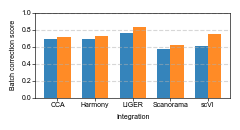

In [85]:
integrations = per_method['Integration'].unique()
x = np.arange(len(integrations))
width = 0.35

best_vals = per_method[per_method['Scenario'] == 'Best'].set_index('Integration').loc[integrations, 'BATCH']
default_vals = per_method[per_method['Scenario'] == 'Default'].set_index('Integration').loc[integrations, 'BATCH']

fig, ax = plt.subplots(figsize=(2.5, 1.4))
ax.bar(x - width/2, default_vals, width, label='Default', color='#1F77B4', alpha=.9)
ax.bar(x + width/2, best_vals, width, label='Best', color='#FF7F0E', alpha=0.9)

ax.set_xlabel('Integration', fontsize=5)
ax.set_ylabel('Batch correction score', fontsize=5)
ax.set_xticks(x)
ax.set_xticklabels(integrations)
# ax.legend()
ax.set_ylim(0, 1)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.tick_params(axis='both', which='major', width=.45, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)

plt.tight_layout()
plt.savefig('../publication_figures/optuna_integration_batch.svg', bbox_inches='tight')
plt.show()

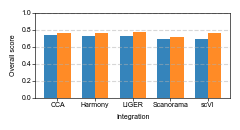

In [86]:
integrations = per_method['Integration'].unique()
x = np.arange(len(integrations))
width = 0.35

best_vals = per_method[per_method['Scenario'] == 'Best'].set_index('Integration').loc[integrations, 'OVERALL']
default_vals = per_method[per_method['Scenario'] == 'Default'].set_index('Integration').loc[integrations, 'OVERALL']

fig, ax = plt.subplots(figsize=(2.5, 1.4))
ax.bar(x - width/2, default_vals, width, label='Default', color='#1F77B4', alpha=.9)
ax.bar(x + width/2, best_vals, width, label='Best', color='#FF7F0E', alpha=0.9)

ax.set_xlabel('Integration', fontsize=5)
ax.set_ylabel('Overall score', fontsize=5)
ax.set_xticks(x)
ax.set_xticklabels(integrations)
# ax.legend()
ax.set_ylim(0, 1)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.tick_params(axis='both', which='major', width=.45, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)

plt.tight_layout()
plt.savefig('../publication_figures/optuna_integration_overall.svg', bbox_inches='tight')
plt.show()

In [87]:
per_method = df.groupby(['Dataset', 'Scenario'])[['BIO', 'BATCH', 'OVERALL']].mean().reset_index()

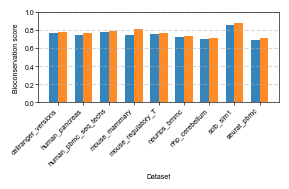

In [88]:
integrations = per_method['Dataset'].unique()
x = np.arange(len(integrations))
width = 0.35

best_vals = per_method[per_method['Scenario'] == 'Best'].set_index('Dataset').loc[integrations, 'BIO']
default_vals = per_method[per_method['Scenario'] == 'Default'].set_index('Dataset').loc[integrations, 'BIO']

fig, ax = plt.subplots(figsize=(3, 2))
ax.bar(x - width/2, default_vals, width, label='Default', color='#1F77B4', alpha=.9)
ax.bar(x + width/2, best_vals, width, label='Best', color='#FF7F0E', alpha=0.9)

ax.set_xlabel('Dataset', fontsize=5)
ax.set_ylabel('Bioconservation score', fontsize=5)
ax.set_xticks(x)
ax.set_xticklabels(integrations, rotation=45, ha='right')
# ax.legend()
ax.set_ylim(0, 1)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.tick_params(axis='both', which='major', width=.45, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)

plt.tight_layout()
plt.savefig('../publication_figures/optuna_dataset_bio.svg', bbox_inches='tight')
plt.show()

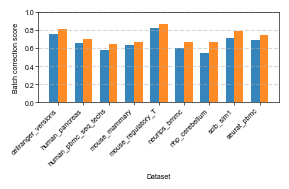

In [89]:
integrations = per_method['Dataset'].unique()
x = np.arange(len(integrations))
width = 0.35

best_vals = per_method[per_method['Scenario'] == 'Best'].set_index('Dataset').loc[integrations, 'BATCH']
default_vals = per_method[per_method['Scenario'] == 'Default'].set_index('Dataset').loc[integrations, 'BATCH']

fig, ax = plt.subplots(figsize=(3, 2))
ax.bar(x - width/2, default_vals, width, label='Default', color='#1F77B4', alpha=.9)
ax.bar(x + width/2, best_vals, width, label='Best', color='#FF7F0E', alpha=0.9)

ax.set_xlabel('Dataset', fontsize=5)
ax.set_ylabel('Batch correction score', fontsize=5)
ax.set_xticks(x)
ax.set_xticklabels(integrations, rotation=45, ha='right')
# ax.legend()
ax.set_ylim(0, 1)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.tick_params(axis='both', which='major', width=.45, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)

plt.tight_layout()
plt.savefig('../publication_figures/optuna_dataset_batch.svg', bbox_inches='tight')
plt.show()

/tmp/ipykernel_3569376/3512617455.py:23: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


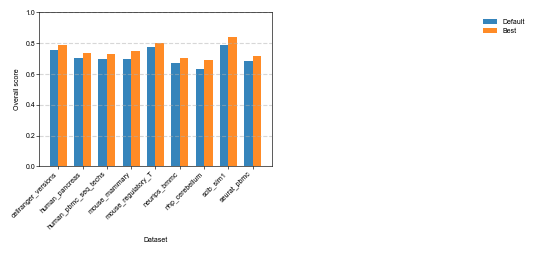

In [99]:
integrations = per_method['Dataset'].unique()
x = np.arange(len(integrations))
width = 0.35

best_vals = per_method[per_method['Scenario'] == 'Best'].set_index('Dataset').loc[integrations, 'OVERALL']
default_vals = per_method[per_method['Scenario'] == 'Default'].set_index('Dataset').loc[integrations, 'OVERALL']

fig, ax = plt.subplots(figsize=(3, 2))
ax.bar(x - width/2, default_vals, width, label='Default', color='#1F77B4', alpha=.9)
ax.bar(x + width/2, best_vals, width, label='Best', color='#FF7F0E', alpha=0.9)

ax.set_xlabel('Dataset', fontsize=5)
ax.set_ylabel('Overall score', fontsize=5)
ax.set_xticks(x)
ax.set_xticklabels(integrations, rotation=45, ha='right')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(2,  1), fontsize=5)
ax.set_ylim(0, 1)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.tick_params(axis='both', which='major', width=.45, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)

plt.tight_layout()
plt.savefig('../publication_figures/optuna_dataset_overall.svg', bbox_inches='tight')
plt.show()

In [10]:
pivoted = df.pivot(
    index=['Integration', 'Dataset'],
    columns='Scenario',
    values=['BIO', 'BATCH', 'OVERALL']
)

diff_df = (pivoted.xs('Best', level='Scenario', axis=1) - 
           pivoted.xs('Default', level='Scenario', axis=1)).reset_index()

In [11]:
diff_df.groupby('Integration')[['BIO', 'BATCH', 'OVERALL']].mean()

,BIO,BATCH,OVERALL
Integration,,,
CCA,0.008527,0.022397,0.014075
Harmony,0.015038,0.045243,0.027120
LIGER,0.039168,0.060468,0.047688
Scanorama,0.017474,0.037581,0.025517
scVI,0.031639,0.143319,0.076311


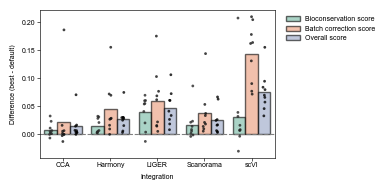

In [13]:
melted_df = diff_df.melt(
    id_vars=['Integration', 'Dataset'],
    value_vars=['BIO', 'BATCH', 'OVERALL'],
    var_name='Metric',
    value_name='Difference'
)

melted_df['Metric'] = melted_df['Metric'].replace({
    'BIO': 'Bioconservation score',
    'BATCH': "Batch correction score",
    "OVERALL": "Overall score"
})

# 2. Set up the figure
plt.figure(figsize=(4, 2))

# 3. Bar plot for the mean difference
ax = sns.barplot(
    data=melted_df,
    x='Integration',
    y='Difference',
    hue='Metric',
    estimator='mean',
    errorbar=None,
    alpha=0.6,
    palette='Set2',
    edgecolor='black',
    linewidth=1
)

# 4. Strip plot for the individual dataset points
sns.stripplot(
    data=melted_df,
    x='Integration',
    y='Difference',
    hue='Metric',
    dodge=True,        # Aligns dots with their corresponding bar
    jitter=0.08,       # Adds a slight spread so overlapping points are visible
    size=2,
    palette='dark:black',
    alpha=0.8,
    ax=ax,
    legend=False       # Prevents creating duplicate legend entries
)

# 5. Formatting
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('Integration', fontsize=5)
plt.ylabel('Difference (best - default)', fontsize=5)
plt.legend(title='', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=5, frameon=False)
ax.tick_params(axis='both', which='major', width=.45, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)

plt.tight_layout()
plt.savefig('../publication_figures/optuna_integration_bar.svg', bbox_inches='tight')
plt.show()

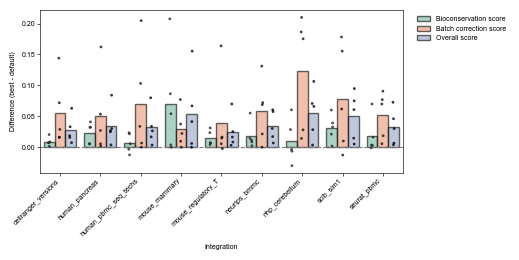

In [14]:
melted_df = diff_df.melt(
    id_vars=['Integration', 'Dataset'],
    value_vars=['BIO', 'BATCH', 'OVERALL'],
    var_name='Metric',
    value_name='Difference'
)

melted_df['Metric'] = melted_df['Metric'].replace({
    'BIO': 'Bioconservation score',
    'BATCH': "Batch correction score",
    "OVERALL": "Overall score"
})

# 2. Set up the figure
plt.figure(figsize=(5.3, 2.7))

# 3. Bar plot for the mean difference
ax = sns.barplot(
    data=melted_df,
    x='Dataset',
    y='Difference',
    hue='Metric',
    estimator='mean',
    errorbar=None,
    alpha=0.6,
    palette='Set2',
    edgecolor='black',
    linewidth=1
)

# 4. Strip plot for the individual dataset points
sns.stripplot(
    data=melted_df,
    x='Dataset',
    y='Difference',
    hue='Metric',
    dodge=True,        # Aligns dots with their corresponding bar
    jitter=0.08,       # Adds a slight spread so overlapping points are visible
    size=2,
    palette='dark:black',
    alpha=0.8,
    ax=ax,
    legend=False       # Prevents creating duplicate legend entries
)

# 5. Formatting
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('Integration', fontsize=5)
plt.ylabel('Difference (best - default)', fontsize=5)
plt.legend(title='', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=5, frameon=False)
ax.tick_params(axis='both', which='major', width=.45, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels
plt.tight_layout()
plt.savefig('../publication_figures/optuna_dataset_bar.svg', bbox_inches='tight')
plt.show()